In [1]:
import sklearn

print(sklearn.__version__)

1.6.0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, log_loss, roc_auc_score

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [3]:
train = pd.read_csv("ucse-ai-2026/solicitudes_train.csv")
bank = pd.read_csv("ucse-ai-2026/comportamiento_bancario.csv")
test = pd.read_csv("ucse-ai-2026/solicitudes_test.csv")

In [4]:
train.shape
bank.shape
test.shape

(3061, 7)

In [5]:
#Obtenemos información básica de los conjuntos de datos

In [6]:
train.head()

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final
0,1,12698,7900,0.2333,4461,Consumo,2025-04,1
1,2,20744,17400,0.2507,3889,Vivienda,2025-12,1
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06,0
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07,1
4,5,24719,6600,0.2314,3357,Otros,2025-01,1


In [7]:
bank.head()

,ID_Usuario,Mes_Referencia,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas
0,1,2024-01,12768.11,3
1,1,2024-02,15817.67,3
2,1,2024-03,13138.66,0
3,1,2024-04,19453.13,0
4,1,2024-05,14943.44,59


In [8]:
test.head()

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud
0,32417,27074,2300,0.2771,2596,Consumo,2026-01
1,32418,28172,10900,0.3291,6905,Consumo,2026-01
2,32419,27547,1300,0.2485,3707,Educacion,2026-01
3,32420,27689,1600,0.2699,3314,Consumo,2026-01
4,32421,26219,900,0.2317,3870,Educacion,2026-01


In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32416 entries, 0 to 32415
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID_Solicitud      32416 non-null  int64  
 1   ID_Usuario        32416 non-null  int64  
 2   Monto_Solicitado  32416 non-null  int64  
 3   Tasa_Interes      32416 non-null  float64
 4   Ingreso_Mensual   32416 non-null  int64  
 5   Motivo_Prestamo   32416 non-null  object 
 6   Fecha_Solicitud   32416 non-null  object 
 7   Estado_Final      32416 non-null  int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 2.0+ MB


In [10]:
bank.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 661139 entries, 0 to 661138
Data columns (total 4 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID_Usuario                661139 non-null  int64  
 1   Mes_Referencia            661139 non-null  object 
 2   Saldo_Promedio_Mensual    661139 non-null  float64
 3   Dias_Atraso_Otras_Deudas  661139 non-null  int64  
dtypes: float64(1), int64(2), object(1)
memory usage: 20.2+ MB


In [11]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3061 entries, 0 to 3060
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID_Solicitud      3061 non-null   int64  
 1   ID_Usuario        3061 non-null   int64  
 2   Monto_Solicitado  3061 non-null   int64  
 3   Tasa_Interes      3061 non-null   float64
 4   Ingreso_Mensual   3061 non-null   int64  
 5   Motivo_Prestamo   3061 non-null   object 
 6   Fecha_Solicitud   3061 non-null   object 
dtypes: float64(1), int64(4), object(2)
memory usage: 167.5+ KB


In [12]:
#Obtenemos información estadística de los conjuntos de datos

In [13]:
train.describe()

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Estado_Final
count,32416.000000,32416.000000,32416.000000,32416.000000,32416.000000,32416.000000
mean,16208.500000,13008.947372,14290.097483,0.259580,4214.475938,0.840480
std,9357.837499,7464.560523,12995.295179,0.032333,2498.904569,0.366166
min,1.000000,1.000000,500.000000,0.147600,353.000000,0.000000
25%,8104.750000,6552.000000,5700.000000,0.237300,2481.000000,1.000000
50%,16208.500000,12996.500000,10200.000000,0.258300,3621.000000,1.000000
75%,24312.250000,19426.000000,18100.000000,0.280600,5276.000000,1.000000
max,32416.000000,25931.000000,70000.000000,0.379900,22000.000000,1.000000


In [14]:
bank.describe()

,ID_Usuario,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas
count,661139.000000,661139.000000,661139.000000
mean,14492.824615,5463.296614,8.950755
std,8368.125761,5473.861364,13.199638
min,1.000000,3.300000,0.000000
25%,7247.000000,2061.955000,1.000000
50%,14489.000000,3974.280000,5.000000
75%,21739.000000,7082.925000,10.000000
max,28993.000000,165915.350000,90.000000


In [15]:
#Verificamos que no hayan datos nulos

In [16]:
train.isnull().sum()

ID_Solicitud        0
ID_Usuario          0
Monto_Solicitado    0
Tasa_Interes        0
Ingreso_Mensual     0
Motivo_Prestamo     0
Fecha_Solicitud     0
Estado_Final        0
dtype: int64

In [17]:
bank.isnull().sum()

ID_Usuario                  0
Mes_Referencia              0
Saldo_Promedio_Mensual      0
Dias_Atraso_Otras_Deudas    0
dtype: int64

In [18]:
test.isnull().sum()

ID_Solicitud        0
ID_Usuario          0
Monto_Solicitado    0
Tasa_Interes        0
Ingreso_Mensual     0
Motivo_Prestamo     0
Fecha_Solicitud     0
dtype: int64

In [19]:
#Verificamos que no hayan datos duplicados

In [20]:
train.duplicated().sum()

0

In [21]:
bank.duplicated().sum()

0

In [22]:
test.duplicated().sum()

0

In [23]:
#Verificamos que los valores de algunos campos no sean ilógicos

In [24]:
train[train["Monto_Solicitado"] < 0]

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final


In [25]:
train[train["Ingreso_Mensual"] < 0]

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final


In [26]:
bank[bank["Dias_Atraso_Otras_Deudas"] < 0]

,ID_Usuario,Mes_Referencia,Saldo_Promedio_Mensual,Dias_Atraso_Otras_Deudas


In [27]:
#Verificamos la cantidad de personas que pagaron y la cantidad de personas que quedaron en default

In [28]:
train["Estado_Final"].value_counts()

Estado_Final
1    27245
0     5171
Name: count, dtype: int64

In [29]:
#Verificamos la proporción de personas que pagaron y la proporción de personas que quedaron en default

In [30]:
train["Estado_Final"].value_counts(normalize=True)

Estado_Final
1    0.84048
0    0.15952
Name: proportion, dtype: float64

In [31]:
#Verificamos la cantidad de veces que se hicieron préstamos para cada motivo

In [32]:
train["Motivo_Prestamo"].value_counts()

Motivo_Prestamo
Consumo      9049
Vivienda     5761
Vehiculo     4256
Otros        3973
Educacion    3876
Salud        2884
Negocio      2617
Name: count, dtype: int64

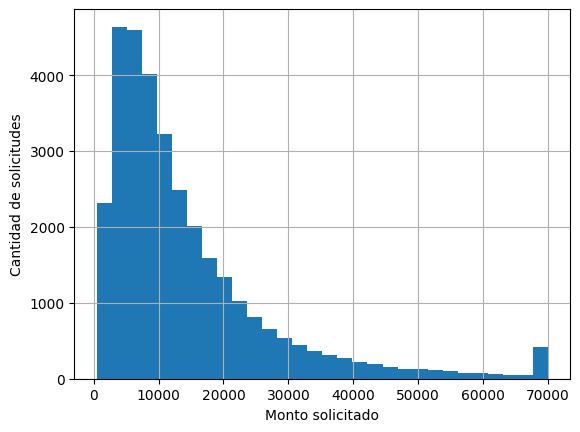

In [33]:
train["Monto_Solicitado"].hist(bins=30)

plt.xlabel("Monto solicitado")
plt.ylabel("Cantidad de solicitudes")
plt.show()

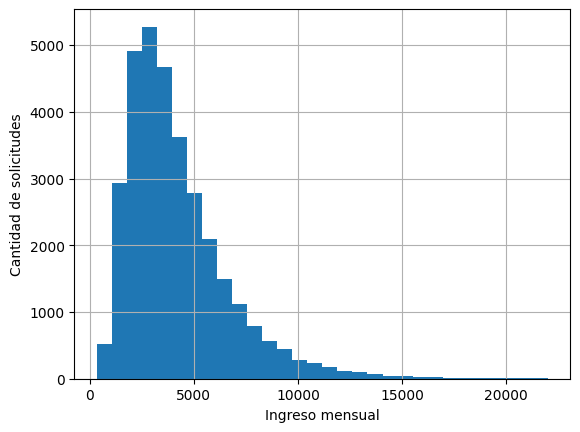

In [34]:
train["Ingreso_Mensual"].hist(bins=30)

plt.xlabel("Ingreso mensual")
plt.ylabel("Cantidad de solicitudes")
plt.show()

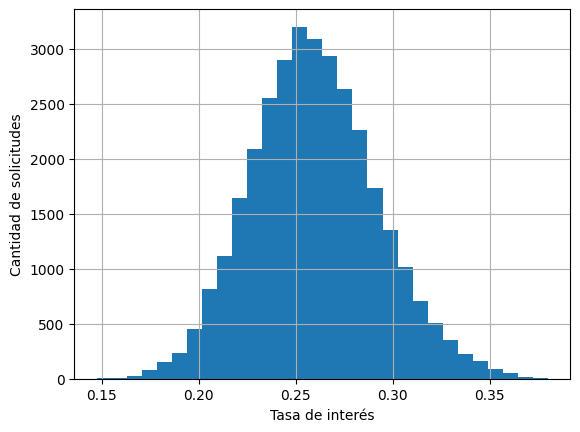

In [35]:
train["Tasa_Interes"].hist(bins=30)

plt.xlabel("Tasa de interés")
plt.ylabel("Cantidad de solicitudes")
plt.show()

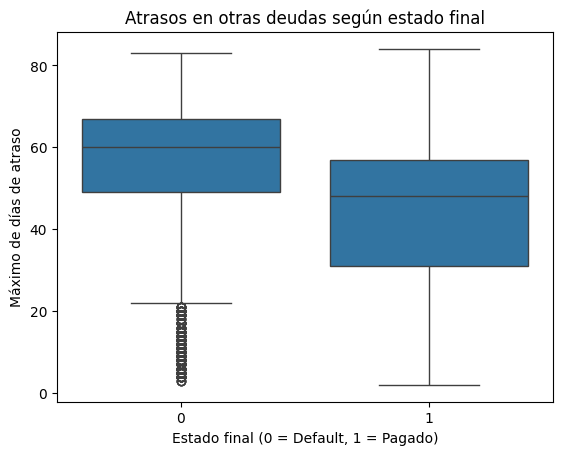

In [36]:
# Hipótesis 1:
# Los usuarios con más atrasos en otras deudas tienen mayor probabilidad de default.

# Un usuario puede tener hasta 24 registros en comportamiento_bancario.
# Tomamos el máximo de días de atraso registrado para cada usuario.
atrasos_usuario = (
    bank.groupby("ID_Usuario")["Dias_Atraso_Otras_Deudas"]
    .max()
    .reset_index()
)

train_grafico = train.merge(
    atrasos_usuario,
    on="ID_Usuario",
    how="left"
)

sns.boxplot(
    data=train_grafico,
    x="Estado_Final",
    y="Dias_Atraso_Otras_Deudas"
)

plt.title("Atrasos en otras deudas según estado final")
plt.xlabel("Estado final (0 = Default, 1 = Pagado)")
plt.ylabel("Máximo de días de atraso")
plt.show()

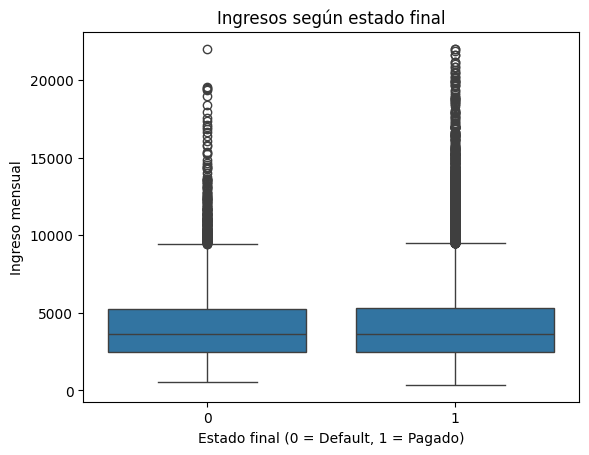

In [37]:
# Hipótesis 2:
# Los usuarios con mayores ingresos tienen mayor probabilidad de pagar.

sns.boxplot(
    data=train,
    x="Estado_Final",
    y="Ingreso_Mensual"
)

plt.title("Ingresos según estado final")
plt.xlabel("Estado final (0 = Default, 1 = Pagado)")
plt.ylabel("Ingreso mensual")
plt.show()

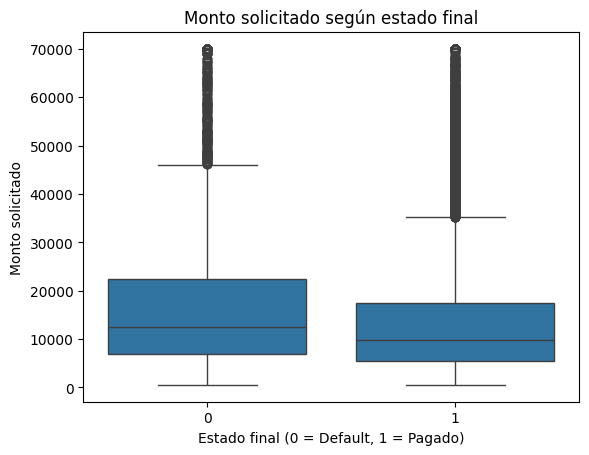

In [38]:
# Hipótesis 3:
# Los préstamos de mayor monto tienen mayor probabilidad de default.

sns.boxplot(
    data=train,
    x="Estado_Final",
    y="Monto_Solicitado"
)

plt.title("Monto solicitado según estado final")
plt.xlabel("Estado final (0 = Default, 1 = Pagado)")
plt.ylabel("Monto solicitado")
plt.show()

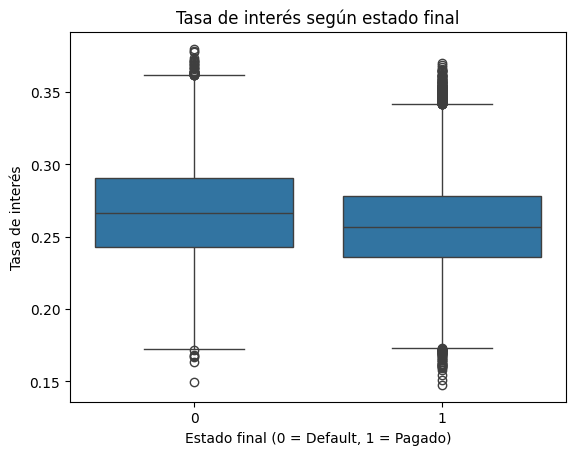

In [39]:
# Hipótesis 4:
# La tasa de interés está relacionada con el resultado del préstamo.

sns.boxplot(
    data=train,
    x="Estado_Final",
    y="Tasa_Interes"
)

plt.title("Tasa de interés según estado final")
plt.xlabel("Estado final (0 = Default, 1 = Pagado)")
plt.ylabel("Tasa de interés")
plt.show()

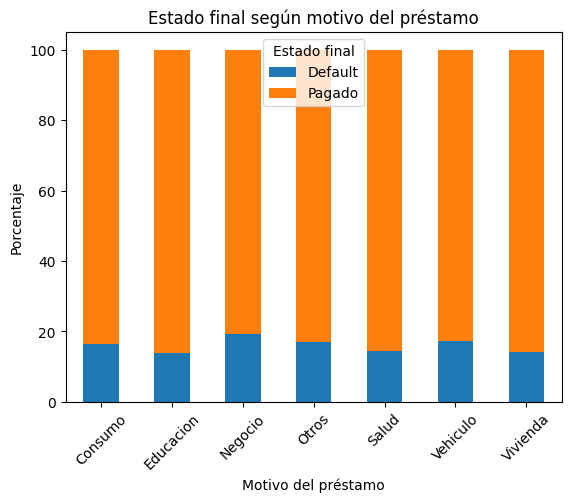

In [40]:
# Hipótesis 5:
# El motivo del préstamo está relacionado con el resultado.

tabla = pd.crosstab(
    train["Motivo_Prestamo"],
    train["Estado_Final"],
    normalize="index"
) * 100

tabla.plot(kind="bar", stacked=True)

plt.title("Estado final según motivo del préstamo")
plt.xlabel("Motivo del préstamo")
plt.ylabel("Porcentaje")
plt.legend(
    title="Estado final",
    labels=["Default", "Pagado"]
)
plt.xticks(rotation=45)
plt.show()

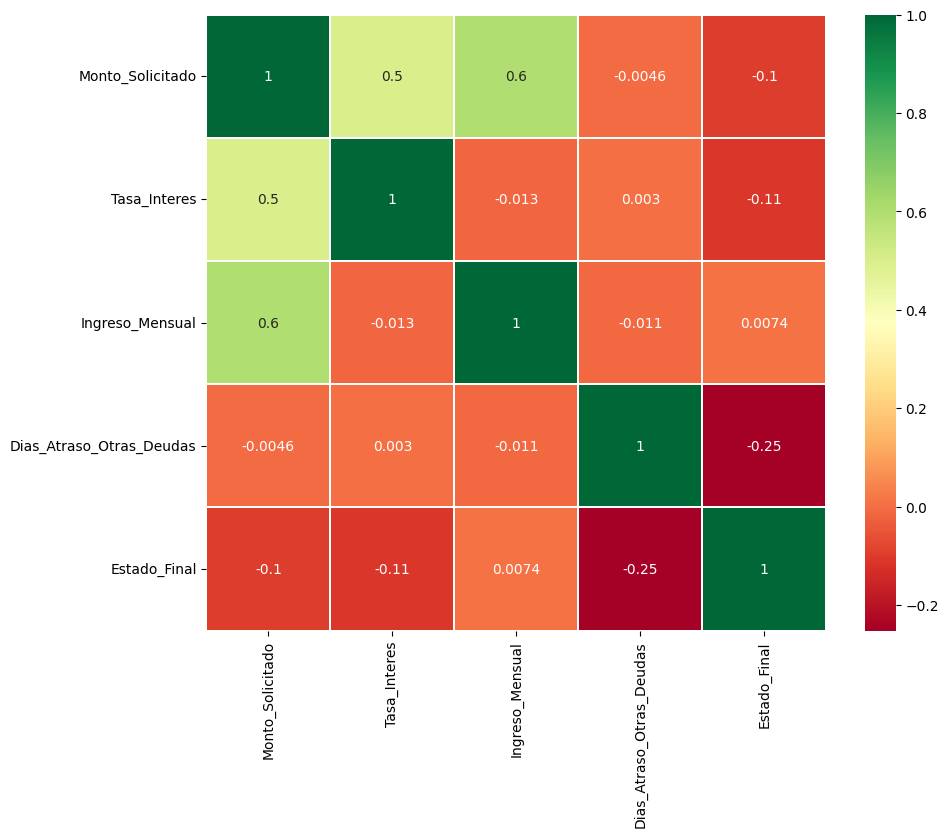

In [41]:
# Obtener el máximo histórico de días de atraso por usuario
atrasos_usuario = (
    bank.groupby("ID_Usuario")["Dias_Atraso_Otras_Deudas"]
    .max()
    .reset_index()
)

# Unirlo con las solicitudes
train_correlacion = train.merge(
    atrasos_usuario,
    on="ID_Usuario",
    how="left"
)

# Cuadro de correlación
correlacion = train_correlacion[
    [
        "Monto_Solicitado",
        "Tasa_Interes",
        "Ingreso_Mensual",
        "Dias_Atraso_Otras_Deudas",
        "Estado_Final"
    ]
].corr()

sns.heatmap(
    correlacion,
    annot=True,
    cmap="RdYlGn",
    linewidths=0.2
)

fig = plt.gcf()
fig.set_size_inches(10, 8)

plt.show()
#1 → correlación positiva perfecta.
#0 → no hay correlación lineal.
#-1 → correlación negativa perfecta.

In [42]:
# 1. Crear el máximo y el promedio de días de atraso para train y test

atrasos = bank.groupby("ID_Usuario")["Dias_Atraso_Otras_Deudas"]

max_atraso = atrasos.max().rename("max_dias_atraso")
promedio_atraso = atrasos.mean().rename("promedio_dias_atraso")

train_model = train.merge(
    max_atraso,
    on="ID_Usuario",
    how="left"
)

train_model = train_model.merge(
    promedio_atraso,
    on="ID_Usuario",
    how="left"
)

test_model = test.merge(
    max_atraso,
    on="ID_Usuario",
    how="left"
)

test_model = test_model.merge(
    promedio_atraso,
    on="ID_Usuario",
    how="left"
)


# 2. Variables que vamos a utilizar

variables = [
    "max_dias_atraso",
    "promedio_dias_atraso",
    "Monto_Solicitado",
    "Tasa_Interes"
]

X = train_model[variables]
y = train_model["Estado_Final"]

X_test = test_model[variables]

# ============================================================
# 3. Separar train en entrenamiento y validación
# ============================================================

X_tr, X_val, y_tr, y_val = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)


# ============================================================
# 4. Crear los modelos
# ============================================================

modelos = {

    "Regresión logística": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Árbol": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        max_depth=15,
        min_samples_leaf=15
    )
}


# ============================================================
# 5. Función para evaluar un modelo
# ============================================================

def evaluar_modelo(modelo, X_tr, y_tr, X_val, y_val):

    # ============================================================
    # 1. ENTRENAR EL MODELO
    # ============================================================

    modelo.fit(X_tr, y_tr)


    # ============================================================
    # 2. EVALUAR LAS PREDICCIONES EN TRAIN
    # ============================================================

    # Probabilidad de que cada préstamo sea pagado
    prob_train = modelo.predict_proba(X_tr)[:, 1]

    # Convertir probabilidades en predicciones:
    # 1 = predice que pagará, 0 = predice que habrá default
    pred_train = (prob_train >= 0.5).astype(int)

    # Accuracy: porcentaje de préstamos clasificados correctamente
    accuracy_train = accuracy_score(y_tr, pred_train)

    # Log Loss: evalúa qué tan buenas son las probabilidades.
    # Cuanto menor sea, mejor. Penaliza las predicciones
    # muy seguras cuando resultan equivocadas.
    logloss_train = log_loss(y_tr, prob_train, labels=[0, 1])

    # ROC-AUC: mide qué tan bien distingue préstamos pagados
    # de préstamos en default. Cuanto más cerca de 1, mejor.
    auc_train = roc_auc_score(y_tr, prob_train)


    # ============================================================
    # 3. EVALUAR LAS PREDICCIONES EN VALIDATION
    # ============================================================

    # Predecir usando datos que no se utilizaron para entrenar
    prob_val = modelo.predict_proba(X_val)[:, 1]

    # Convertir probabilidades en predicciones usando el mismo umbral
    pred_val = (prob_val >= 0.5).astype(int)

    # Porcentaje de clasificaciones correctas en validation
    accuracy_val = accuracy_score(y_val, pred_val)

    # Calidad de las probabilidades en validation
    logloss_val = log_loss(y_val, prob_val, labels=[0, 1])

    # Capacidad para distinguir préstamos pagados y defaults
    auc_val = roc_auc_score(y_val, prob_val)


    # ============================================================
    # 4. MOSTRAR Y COMPARAR LAS MÉTRICAS
    # ============================================================

    print("\n--- RENDIMIENTO PREDICTIVO ---")

    print("\nTRAIN:")
    print(f"Accuracy: {accuracy_train:.4f}")
    print(f"Log Loss: {logloss_train:.4f}")
    print(f"ROC-AUC:  {auc_train:.4f}")

    print("\nVALIDATION:")
    print(f"Accuracy: {accuracy_val:.4f}")
    print(f"Log Loss: {logloss_val:.4f}")
    print(f"ROC-AUC:  {auc_val:.4f}")


    # ============================================================
    # 5. CALCULAR LA GANANCIA ECONÓMICA EN VALIDATION
    # ============================================================

    # Recuperar los préstamos originales correspondientes a validation
    resultados = train_model.loc[X_val.index].copy()

    resultados["prob_pagado"] = prob_val

    # Ganancia esperada de cada préstamo:
    # probabilidad de pago * intereses
    # menos probabilidad de default * capital prestado
    resultados["ganancia_esperada"] = (
        resultados["prob_pagado"]
        * resultados["Monto_Solicitado"]
        * resultados["Tasa_Interes"]
        - (1 - resultados["prob_pagado"])
        * resultados["Monto_Solicitado"]
    )

        # Calcular la ganancia esperada por cada dólar prestado
    resultados["ganancia_por_dolar"] = (
        resultados["ganancia_esperada"]
        / resultados["Monto_Solicitado"]
    )

        # Filtrar solo los préstamos con ganancia esperada positiva
    candidatos = resultados[
        resultados["ganancia_por_dolar"] > 0
    ].copy()

    # Ordenar los candidatos por ganancia esperada por dólar
    candidatos = candidatos.sort_values(
        "ganancia_por_dolar",
        ascending=False
    )

    # Seleccionar préstamos sin superar el presupuesto
    presupuesto = 2_000_000
    monto_acumulado = 0

    resultados["aprobado"] = 0

    for idx, fila in candidatos.iterrows():

        monto = fila["Monto_Solicitado"]

        if monto_acumulado + monto <= presupuesto:
            resultados.loc[idx, "aprobado"] = 1
            monto_acumulado += monto

    # Calcular la ganancia real de los préstamos aprobados
    resultados["ganancia_real"] = 0.0

    # Si se pagó, ganamos los intereses
    mask_pago = (
        (resultados["aprobado"] == 1) &
        (resultados["Estado_Final"] == 1)
    )

    resultados.loc[mask_pago, "ganancia_real"] = (
        resultados.loc[mask_pago, "Monto_Solicitado"]
        * resultados.loc[mask_pago, "Tasa_Interes"]
    )

    # Si hubo default, perdemos el capital prestado
    mask_default = (
        (resultados["aprobado"] == 1) &
        (resultados["Estado_Final"] == 0)
    )

    resultados.loc[mask_default, "ganancia_real"] = (
        -resultados.loc[mask_default, "Monto_Solicitado"]
    )

    # Sumar las ganancias y pérdidas reales de validation
    ganancia_neta = resultados["ganancia_real"].sum()

    print(f"\nGanancia neta en validation: ${ganancia_neta:,.2f}")

    # Devolver la ganancia para poder comparar los modelos
    return ganancia_neta


# ============================================================
# 6. COMPARAR LOS MODELOS
# ============================================================

ganancias = {}

for nombre, modelo in modelos.items():

    print("\n" + "=" * 50)
    print(f"MODELO: {nombre}")
    print("=" * 50)

    ganancia = evaluar_modelo(
        modelo,
        X_tr,
        y_tr,
        X_val,
        y_val
    )

    ganancias[nombre] = ganancia


# Ordenar los modelos por ganancia neta obtenida
print("\n--- COMPARACIÓN ECONÓMICA FINAL ---")

for nombre, ganancia in sorted(
    ganancias.items(),
    key=lambda elemento: elemento[1],
    reverse=True
):
    print(f"{nombre} → Ganancia neta: ${ganancia:,.2f}")


MODELO: Regresión logística

--- RENDIMIENTO PREDICTIVO ---

TRAIN:
Accuracy: 0.8619
Log Loss: 0.3317
ROC-AUC:  0.8340

VALIDATION:
Accuracy: 0.8615
Log Loss: 0.3325
ROC-AUC:  0.8313

Ganancia neta en validation: $488,728.79

MODELO: KNN

--- RENDIMIENTO PREDICTIVO ---

TRAIN:
Accuracy: 0.8832
Log Loss: 0.2387
ROC-AUC:  0.9128

VALIDATION:
Accuracy: 0.8469
Log Loss: 1.7252
ROC-AUC:  0.7484

Ganancia neta en validation: $477,457.35

MODELO: Árbol

--- RENDIMIENTO PREDICTIVO ---

TRAIN:
Accuracy: 1.0000
Log Loss: 0.0000
ROC-AUC:  1.0000

VALIDATION:
Accuracy: 0.8001
Log Loss: 7.2050
ROC-AUC:  0.6298

Ganancia neta en validation: $-25,860.12

MODELO: Random Forest

--- RENDIMIENTO PREDICTIVO ---

TRAIN:
Accuracy: 0.8803
Log Loss: 0.2715
ROC-AUC:  0.9084

VALIDATION:
Accuracy: 0.8616
Log Loss: 0.3365
ROC-AUC:  0.8259

Ganancia neta en validation: $394,537.11

--- COMPARACIÓN ECONÓMICA FINAL ---
Regresión logística → Ganancia neta: $488,728.79
KNN → Ganancia neta: $477,457.35
Random Forest

In [43]:
modelo_final = modelos["Random Forest"]

modelo_final.fit(X, y)

RandomForestClassifier(max_depth=15, min_samples_leaf=15, n_estimators=200,
                       random_state=42)

In [44]:
prob_pagado_test = modelo_final.predict_proba(X_test)[:, 1]

resultados = test_model.copy()

resultados["prob_pagado"] = prob_pagado_test

resultados["ganancia_esperada"] = (
    resultados["prob_pagado"]
    * resultados["Monto_Solicitado"]
    * resultados["Tasa_Interes"]
    - (1 - resultados["prob_pagado"])
    * resultados["Monto_Solicitado"]
)

resultados["ganancia_por_dolar"] = (
    resultados["ganancia_esperada"]
    / resultados["Monto_Solicitado"]
)

# Filtrar solo los préstamos con ganancia esperada positiva
candidatos = resultados[
    resultados["ganancia_por_dolar"] > 0
].copy()

# Ordenar los candidatos por ganancia esperada por dólar
candidatos = candidatos.sort_values(
    "ganancia_por_dolar",
    ascending=False
)

In [45]:
presupuesto = 2_000_000
monto_acumulado = 0

resultados["aprobado"] = 0
#Las que no están en candidatos permanecen con aprobado = 0
for idx, fila in candidatos.iterrows():

    monto = fila["Monto_Solicitado"]

    if monto_acumulado + monto <= presupuesto:
        resultados.loc[idx, "aprobado"] = 1
        monto_acumulado += monto

In [46]:
print("Monto total aprobado:", monto_acumulado)
print("Cantidad de préstamos aprobados:", resultados["aprobado"].sum())

entrega = resultados[[
    "ID_Solicitud",
    "aprobado"
]].rename(columns={
    "aprobado": "Decision_Aprobacion"
})

entrega.to_csv(
    "submission.csv",
    index=False
)

Monto total aprobado: 1999900
Cantidad de préstamos aprobados: 820
